EXPLORATORY DATA ANALYSIS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import os
import sys
sys.path.append(os.path.abspath(".."))

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
data: pd.DataFrame = pd.read_csv(r"C:\Users\noir1\verf-url\data\raw\PhiUSIIL_Phishing_URL_Dataset.csv")
data.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


1-legitimate urls, 0-malicious urls

In [3]:
columns: list[str] = data.columns.to_list()
print(columns)

['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


In [4]:
from src.config import url_features, webpage_features, exclude_features
data_mod: pd.DataFrame = data.drop(columns = exclude_features)
data_mod.head()

,URLLength,DomainLength,IsDomainIP,TLD,CharContinuationRate,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,NoOfURLRedirect,HasDescription,NoOfiFrame,HasExternalFormSubmit,HasSubmitButton,HasHiddenFields,HasPasswordField,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,31,24,0,com,1.000000,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,1,0.000000,0.000000,0,0,0,1,0,1,1,0,34,20,28,119,0,124,1
1,23,16,0,de,0.666667,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,1,55.555556,55.555556,1,0,0,0,0,1,0,0,50,9,8,39,0,217,1
2,29,22,0,uk,0.866667,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,1,46.666667,46.666667,0,0,1,0,0,1,1,0,10,2,7,42,2,5,1
3,26,19,0,com,1.000000,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,1,0.000000,0.000000,0,0,0,12,0,1,1,0,3,27,15,22,1,31,1
4,33,26,0,org,1.000000,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,1,100.000000,100.000000,0,1,1,2,0,1,1,0,244,15,34,72,1,85,1


In [5]:
print(f"Shape of the data: {data_mod.shape}")

Shape of the data: (235795, 38)


In [6]:
data_mod['label'].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

In [7]:
data_mod.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 38 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URLLength                   235795 non-null  int64  
 1   DomainLength                235795 non-null  int64  
 2   IsDomainIP                  235795 non-null  int64  
 3   TLD                         235795 non-null  str    
 4   CharContinuationRate        235795 non-null  float64
 5   TLDLength                   235795 non-null  int64  
 6   NoOfSubDomain               235795 non-null  int64  
 7   HasObfuscation              235795 non-null  int64  
 8   NoOfObfuscatedChar          235795 non-null  int64  
 9   ObfuscationRatio            235795 non-null  float64
 10  NoOfLettersInURL            235795 non-null  int64  
 11  LetterRatioInURL            235795 non-null  float64
 12  NoOfDegitsInURL             235795 non-null  int64  
 13  DegitRatioInURL          

In [8]:
data_mod.isnull().sum()

URLLength                     0
DomainLength                  0
IsDomainIP                    0
TLD                           0
CharContinuationRate          0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
HasTitle                      0
DomainTitleMatchScore         0
URLTitleMatchScore            0
HasFavicon                    0
NoOfURLRedirect               0
HasDescription                0
NoOfiFrame                    0
HasExternalFormSubmit         0
HasSubmitButton               0
HasHiddenFields               0
HasPasswordField              0
NoOfImag

In [9]:
print(f"duplicate rows: {data_mod.duplicated().sum()}")
# ohh sheesh, there are so much of exact duplicate rows, need to drop them!
data_mod.drop_duplicates(inplace = True)
print(f"after dropping, duplicate rows: {data_mod.duplicated().sum()}")

duplicate rows: 41979
after dropping, duplicate rows: 0


In [10]:
print(f"shape after dropping : {data_mod.shape}")
data_mod["label"].value_counts()

shape after dropping : (193816, 38)


label
1    134828
0     58988
Name: count, dtype: int64

In [11]:
data_mod.reset_index(drop = True, inplace = True)

In [12]:
data_mod.describe()

,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,NoOfURLRedirect,HasDescription,NoOfiFrame,HasExternalFormSubmit,HasSubmitButton,HasHiddenFields,HasPasswordField,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,193816.000000,193816.000000,193816.00000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000,193816.000000
mean,34.494149,21.177070,0.00324,0.860134,2.745656,1.152211,0.002301,0.028125,0.000156,19.312250,0.511513,1.729331,0.022562,0.068457,0.031705,0.028496,2.252100,0.060686,0.864877,0.904430,56.609603,58.541808,0.423371,0.132198,0.528672,1.925357,0.052942,0.499226,0.441852,0.122209,31.483046,7.640747,12.653955,79.101576,2.885773,59.734232,0.695649
std,44.464652,9.169738,0.05683,0.211375,0.609532,0.571266,0.047915,2.063694,0.004115,31.132217,0.122417,12.859570,0.064027,1.019931,0.202150,0.910106,3.747367,0.031452,0.341856,0.294001,49.195455,48.867345,0.494094,0.338706,0.499179,6.304531,0.223918,0.500001,0.496609,0.327528,86.625635,82.517690,24.063738,192.022848,19.417915,175.865695,0.460133
min,13.000000,4.000000,0.00000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.00000,0.714286,2.000000,1.000000,0.000000,0.000000,0.000000,10.000000,0.435000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.038000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000
50%,27.000000,19.000000,0.00000,1.000000,3.000000,1.000000,0.000000,0.000000,0.000000,14.000000,0.517000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.048000,1.000000,1.000000,100.000000,100.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,15.000000,3.000000,9.000000,40.000000,0.000000,20.000000,1.000000
75%,33.000000,24.000000,0.00000,1.000000,3.000000,1.000000,0.000000,0.000000,0.000000,20.000000,0.588000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.079000,1.000000,1.000000,100.000000,100.000000,1.000000,0.000000,1.000000,2.000000,0.000000,1.000000,1.000000,0.000000,35.000000,9.000000,18.000000,105.000000,2.000000,75.000000,1.000000
max,6097.000000,110.000000,1.00000,1.000000,13.000000,10.000000,1.000000,447.000000,0.348000,5191.000000,0.926000,2011.000000,0.684000,176.000000,4.000000,149.000000,499.000000,0.397000,1.000000,1.000000,100.000000,100.000000,1.000000,1.000000,1.000000,1602.000000,1.000000,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [13]:
numeric_cols: list[str] = data_mod.select_dtypes(include = [np.int64, np.float64]).columns.to_list()
numeric_cols

['URLLength',
 'DomainLength',
 'IsDomainIP',
 'CharContinuationRate',
 'TLDLength',
 'NoOfSubDomain',
 'HasObfuscation',
 'NoOfObfuscatedChar',
 'ObfuscationRatio',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDegitsInURL',
 'DegitRatioInURL',
 'NoOfEqualsInURL',
 'NoOfQMarkInURL',
 'NoOfAmpersandInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpacialCharRatioInURL',
 'IsHTTPS',
 'HasTitle',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'HasFavicon',
 'NoOfURLRedirect',
 'HasDescription',
 'NoOfiFrame',
 'HasExternalFormSubmit',
 'HasSubmitButton',
 'HasHiddenFields',
 'HasPasswordField',
 'NoOfImage',
 'NoOfCSS',
 'NoOfJS',
 'NoOfSelfRef',
 'NoOfEmptyRef',
 'NoOfExternalRef',
 'label']

SOME UNIVARIATE PLOTS

Text(0.5, 1.0, 'Target variable distribution')

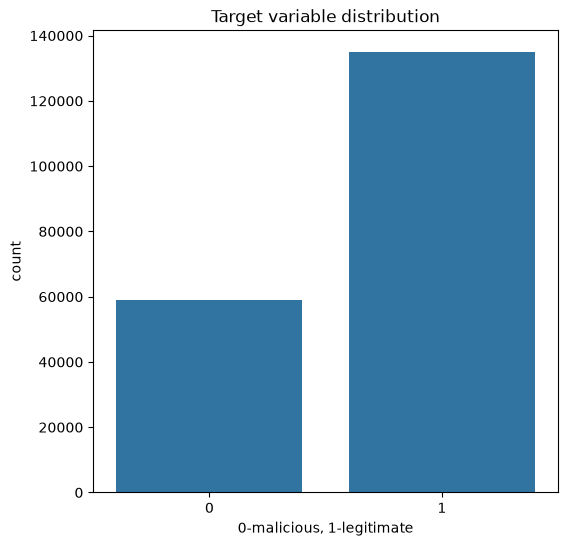

In [18]:
plt.figure(figsize = (6, 6))
sns.countplot(data = data_mod, x = "label")
plt.xlabel("0-malicious, 1-legitimate")
plt.title("Target variable distribution")

NUM_FEATURES (HISTPLOTS)

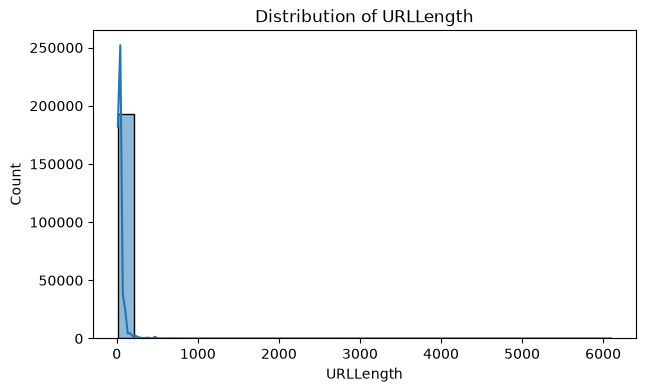

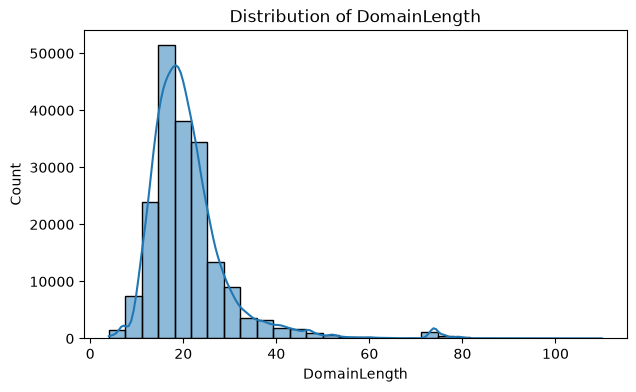

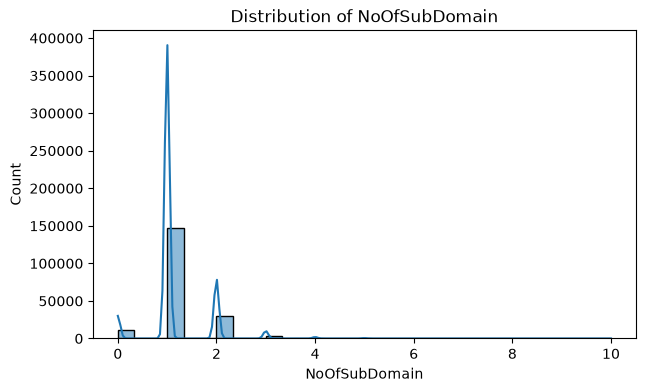

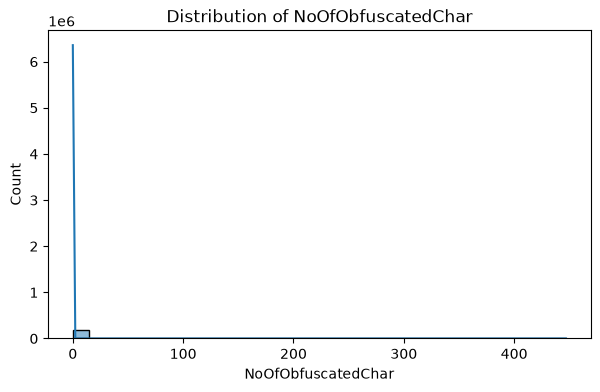

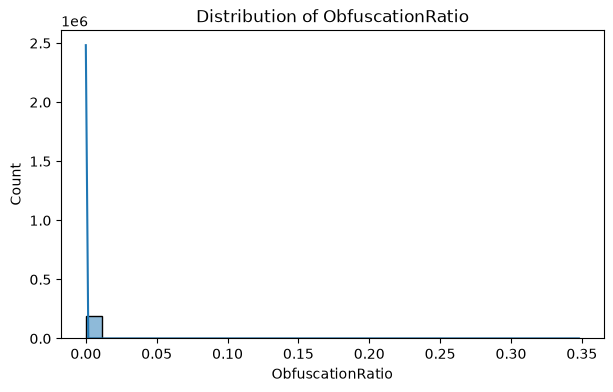

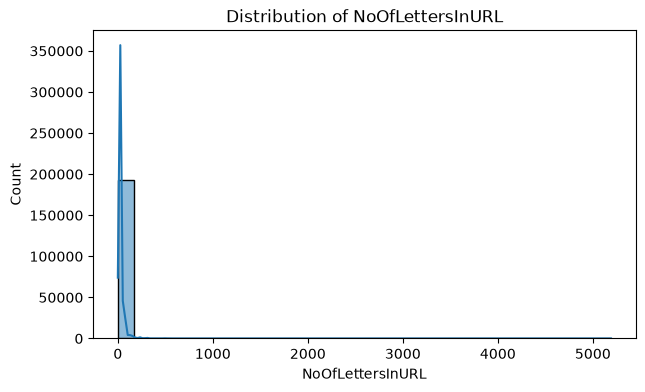

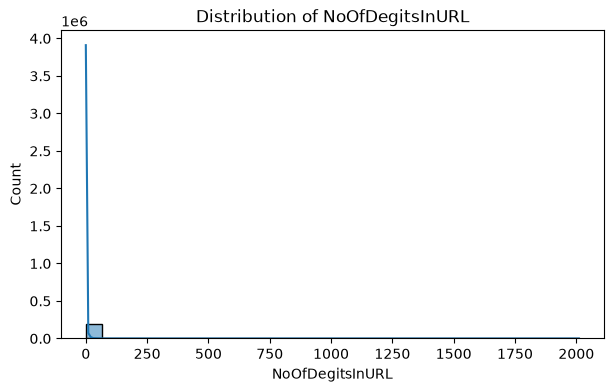

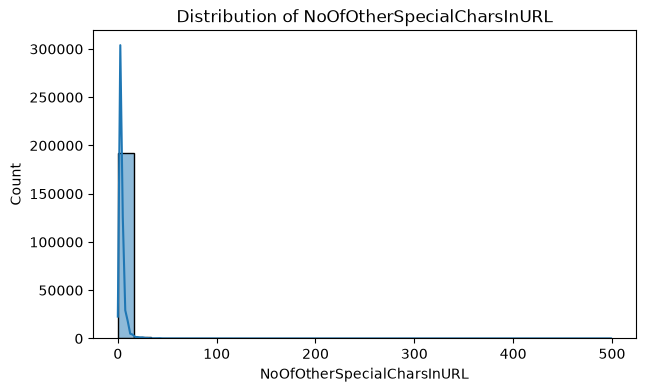

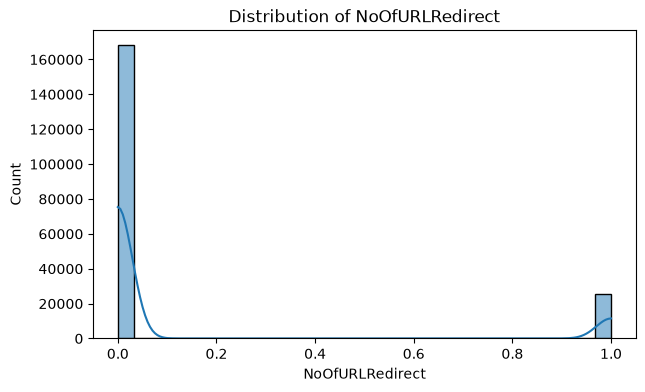

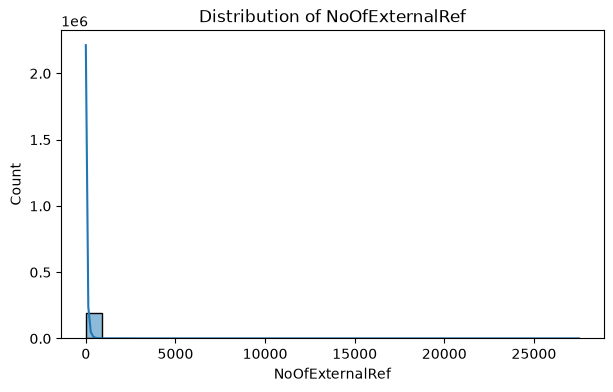

In [ ]:
numerical_features: list[str] = [
    'URLLength',
    'DomainLength',
    'NoOfSubDomain',
    'NoOfObfuscatedChar',
    'ObfuscationRatio',
    'NoOfLettersInURL',
    'NoOfDegitsInURL',
    'NoOfOtherSpecialCharsInURL',
    'NoOfURLRedirect',
    'NoOfExternalRef'
]

for feature in numerical_features:
    plt.figure(figsize = (7, 4))

    sns.histplot(data = data_mod, x = feature, bins = 30, kde = True)

    plt.title(f"Distribution of {feature}")
    plt.show()

NUM_FEATURES (BOXPLOTS)

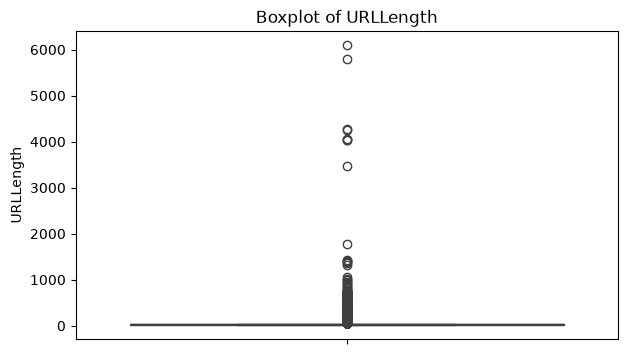

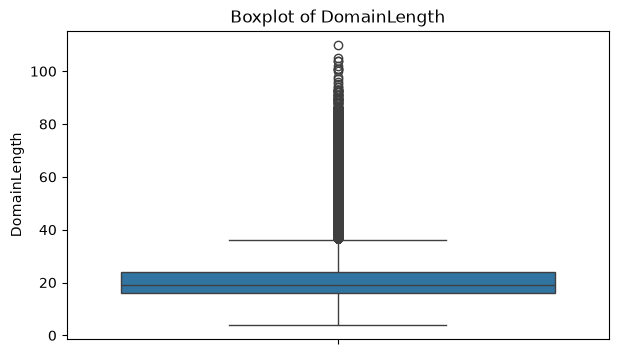

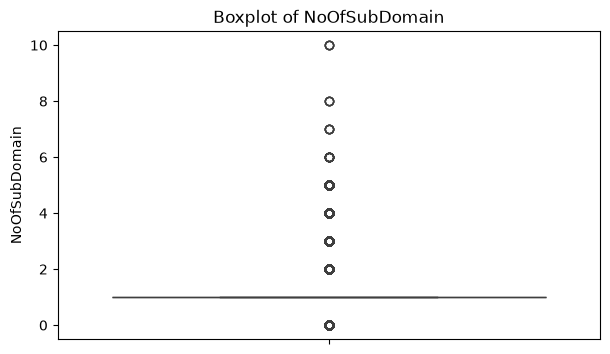

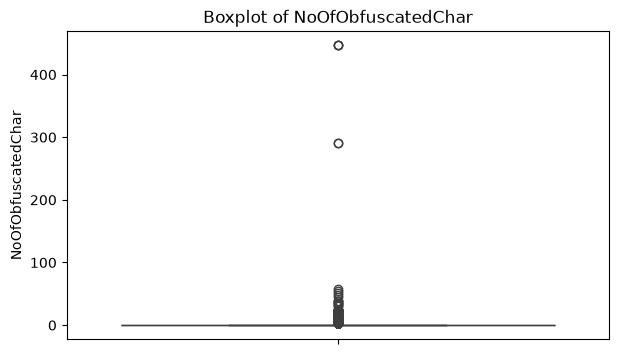

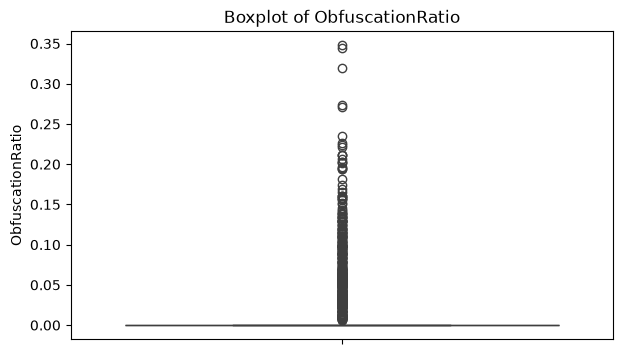

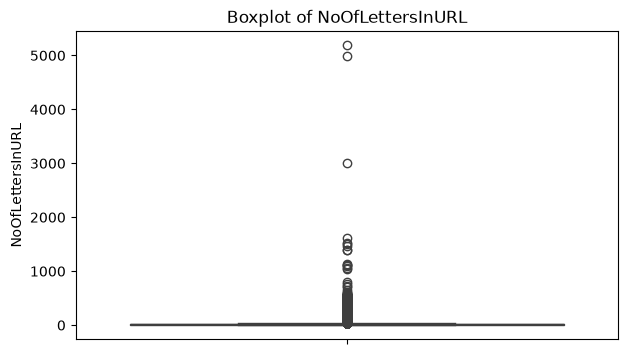

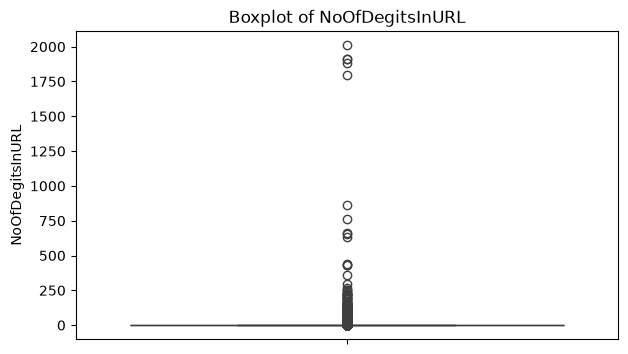

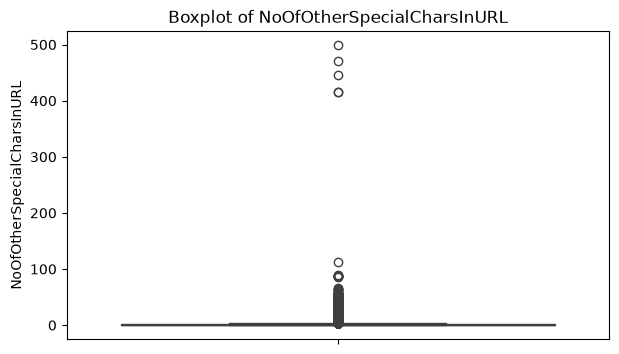

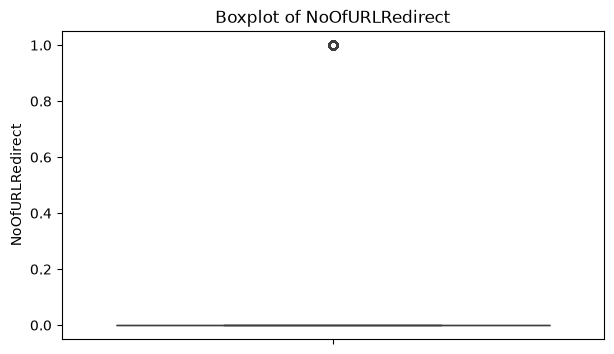

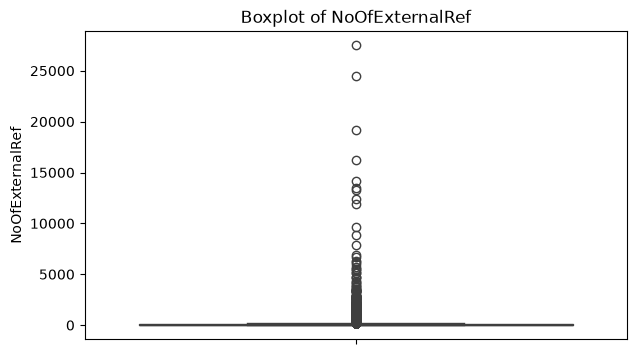

In [ ]:
for feature in numerical_features:
    plt.figure(figsize = (7, 4))

    sns.boxplot(data = data_mod, y = feature)

    plt.title(f"Boxplot of {feature}")
    plt.show()

BINARY_FEATURES (COUNTPLOT)

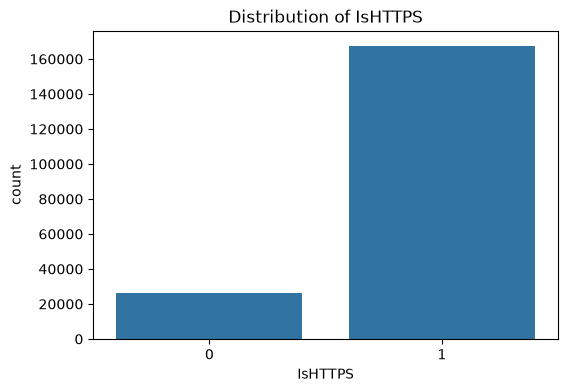

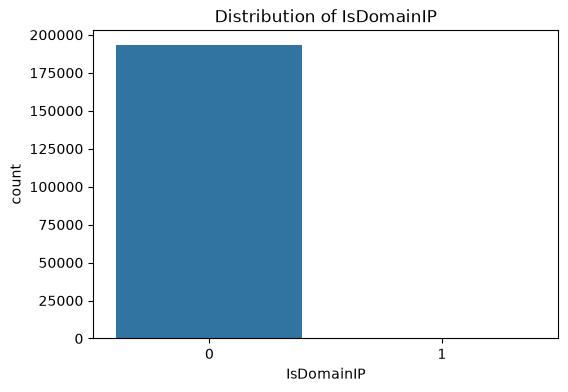

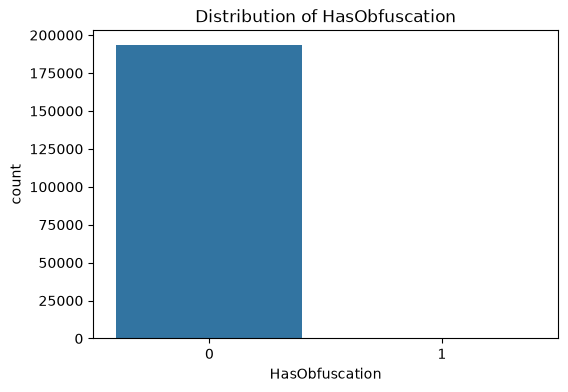

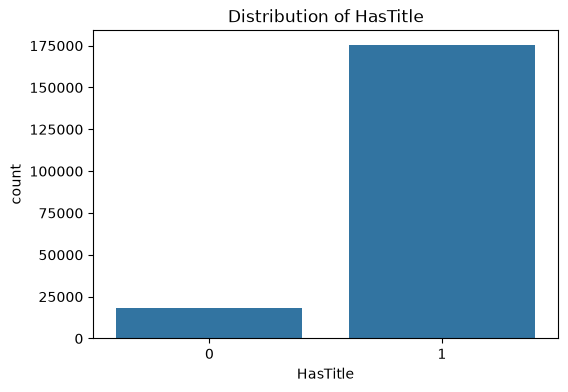

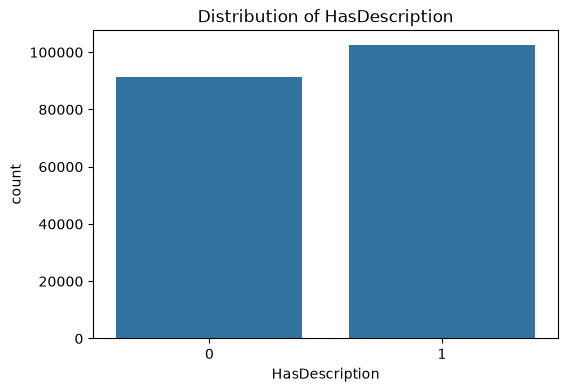

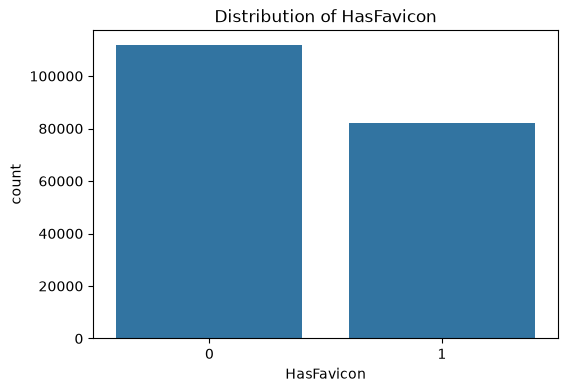

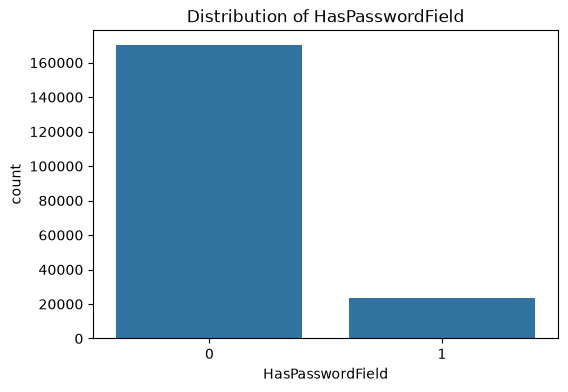

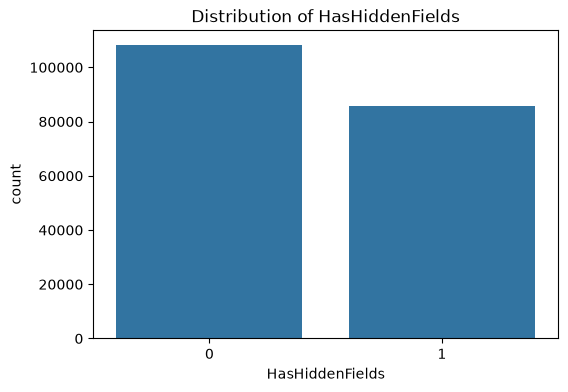

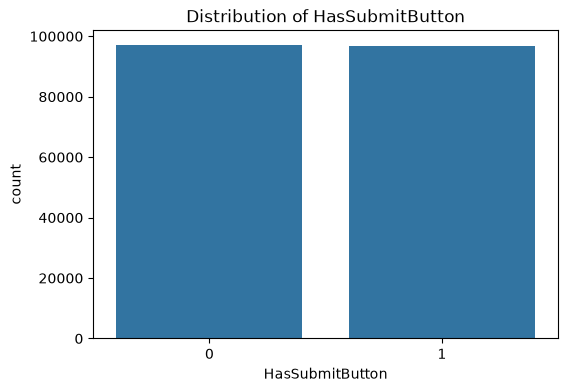

In [22]:
categorical_features = [
    'IsHTTPS',
    'IsDomainIP',
    'HasObfuscation',
    'HasTitle',
    'HasDescription',
    'HasFavicon',
    'HasPasswordField',
    'HasHiddenFields',
    'HasSubmitButton'
]

for feature in categorical_features:
    plt.figure(figsize = (6, 4))

    sns.countplot(data = data_mod, x = feature)

    plt.title(f"Distribution of {feature}")
    plt.show()

In [23]:
for feature in categorical_features:
    print(f"{feature} value-counts : \n{data_mod[feature].value_counts()}\n")

IsHTTPS value-counts : 
IsHTTPS
1    167627
0     26189
Name: count, dtype: int64

IsDomainIP value-counts : 
IsDomainIP
0    193188
1       628
Name: count, dtype: int64

HasObfuscation value-counts : 
HasObfuscation
0    193370
1       446
Name: count, dtype: int64

HasTitle value-counts : 
HasTitle
1    175293
0     18523
Name: count, dtype: int64

HasDescription value-counts : 
HasDescription
1    102465
0     91351
Name: count, dtype: int64

HasFavicon value-counts : 
HasFavicon
0    111760
1     82056
Name: count, dtype: int64

HasPasswordField value-counts : 
HasPasswordField
0    170130
1     23686
Name: count, dtype: int64

HasHiddenFields value-counts : 
HasHiddenFields
0    108178
1     85638
Name: count, dtype: int64

HasSubmitButton value-counts : 
HasSubmitButton
0    97058
1    96758
Name: count, dtype: int64



BIVARIATE ANALYSIS

NUM_FEATURES vs LABEL (BOXPLOTS)

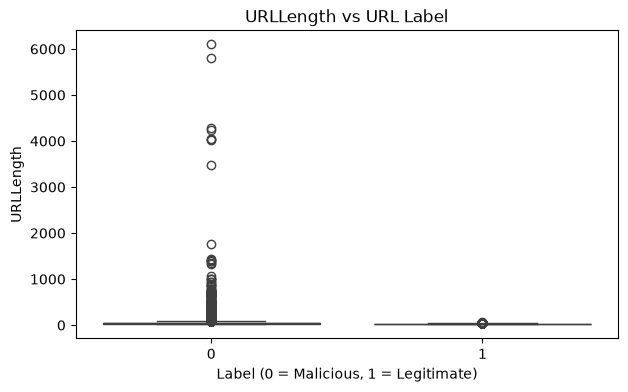

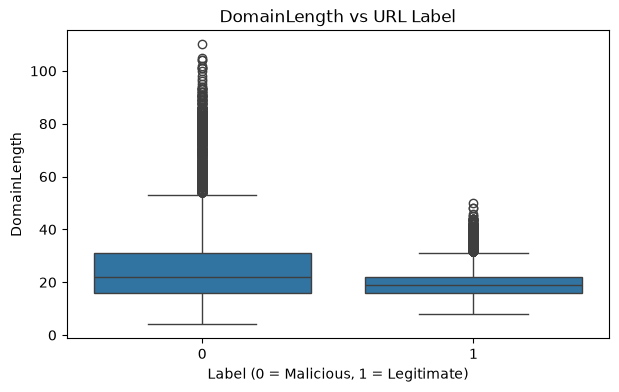

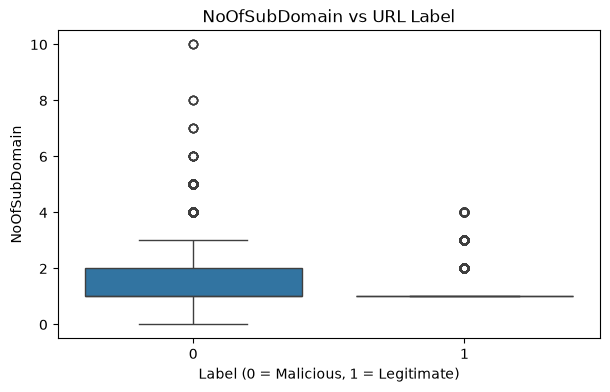

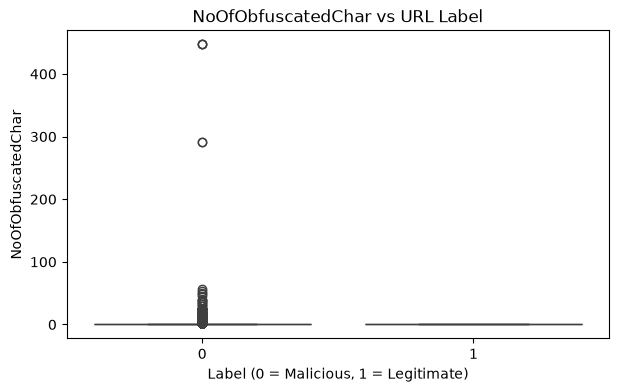

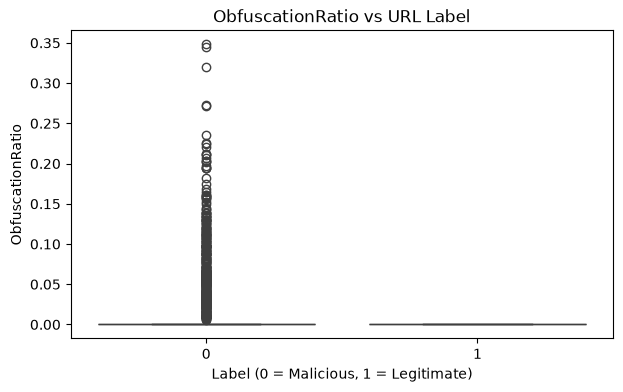

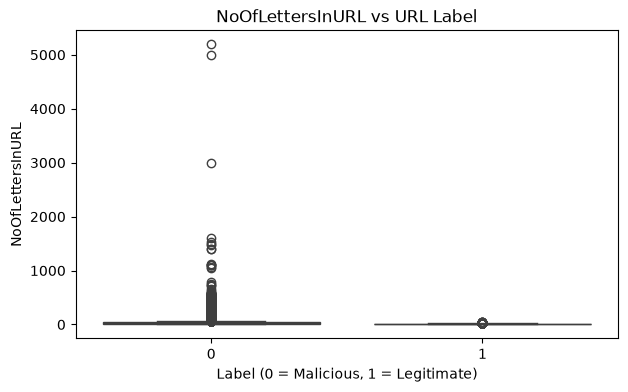

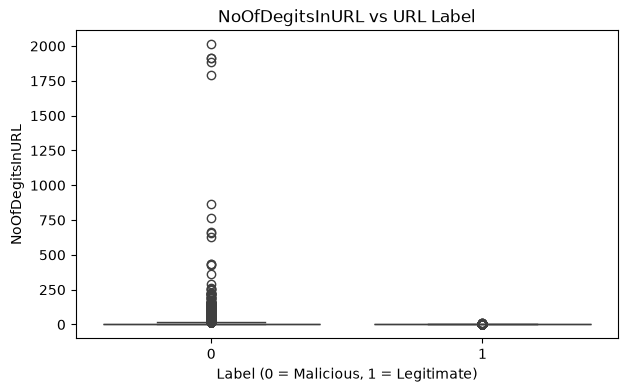

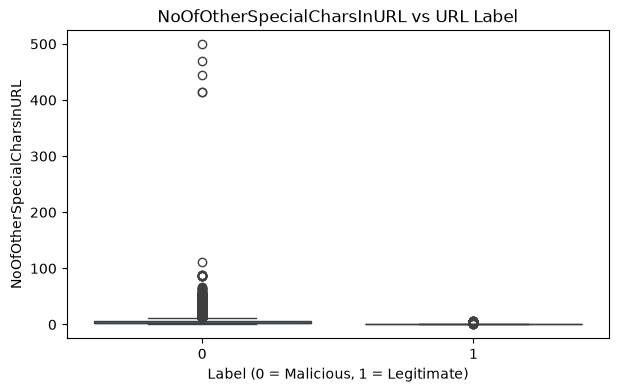

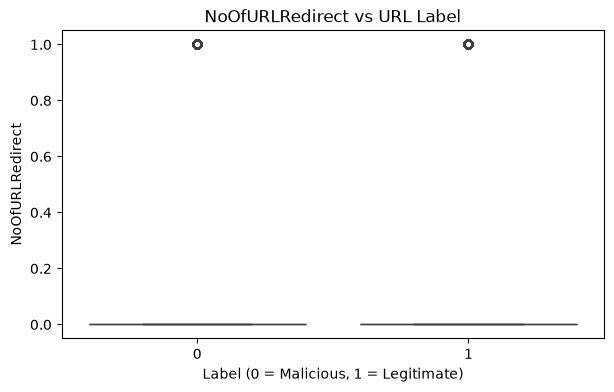

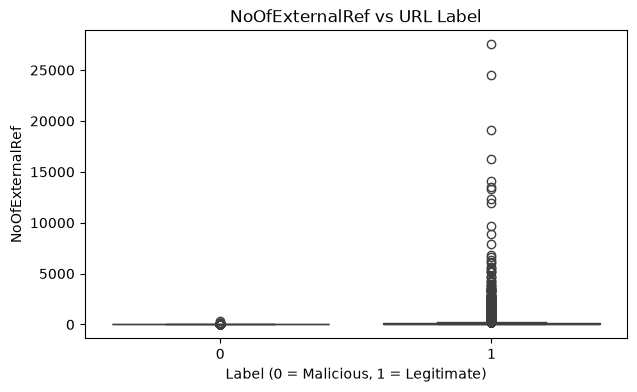

In [24]:
for feature in numerical_features:
    plt.figure(figsize = (7, 4))

    sns.boxplot(
        data = data_mod,
        x = 'label',
        y = feature
    )

    plt.title(f"{feature} vs URL Label")
    plt.xlabel("Label (0 = Malicious, 1 = Legitimate)")

    plt.show()

NUM_FEATURES vs LABEL (KDE-PLOTS)

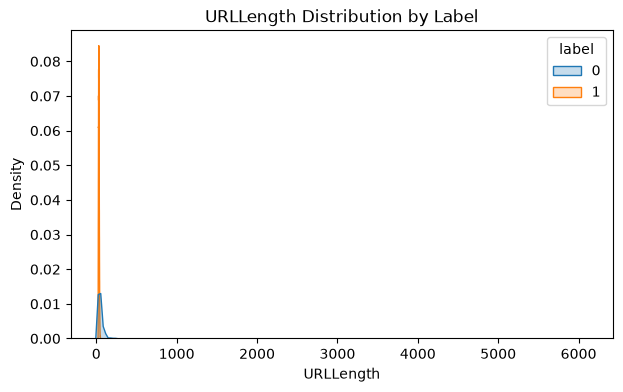

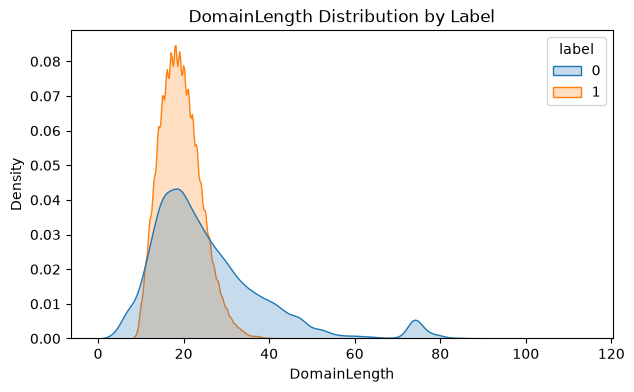

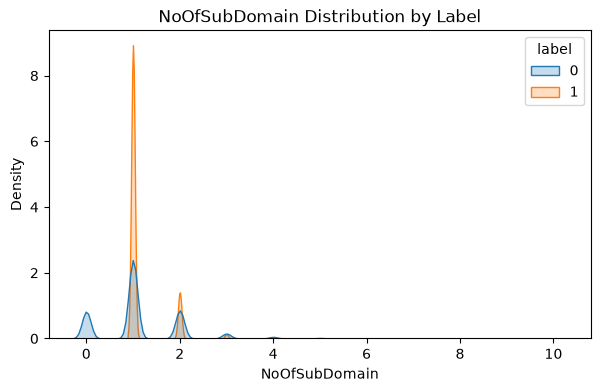

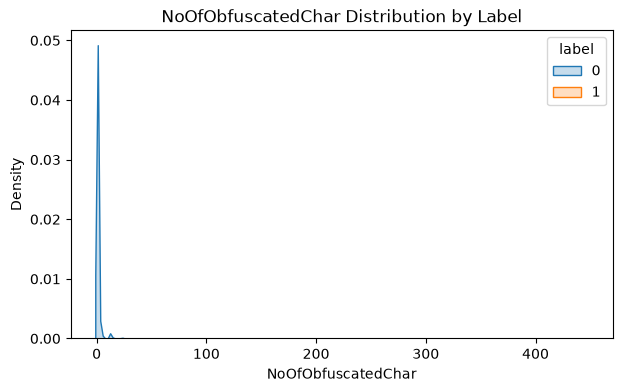

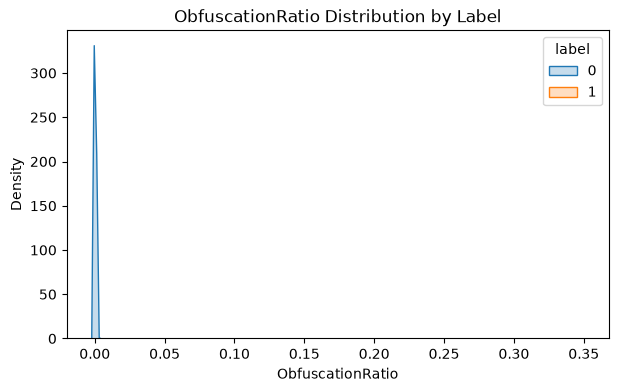

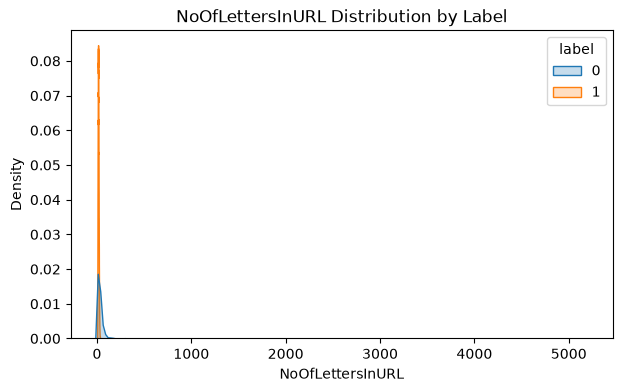

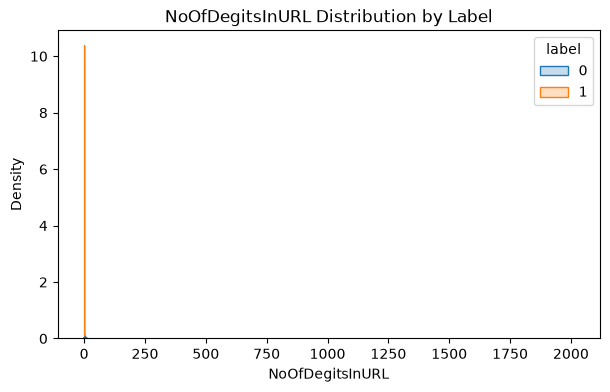

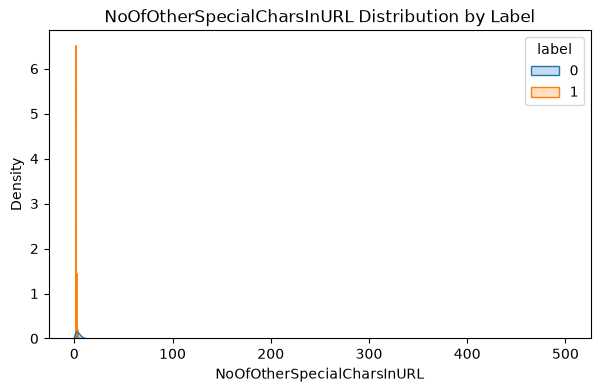

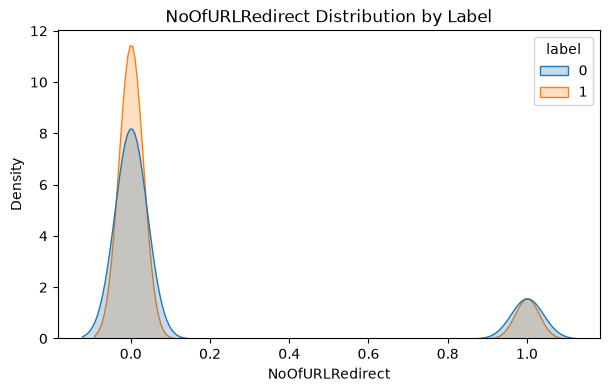

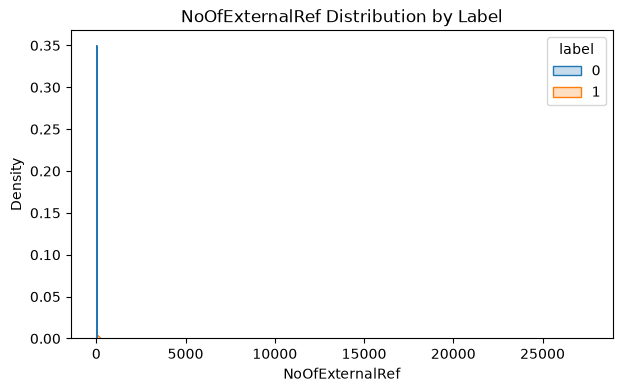

In [25]:
for feature in numerical_features:
    plt.figure(figsize = (7, 4))

    sns.kdeplot(
        data = data_mod,
        x = feature,
        hue = 'label',
        fill = True,
        common_norm = False
    )

    plt.title(f"{feature} Distribution by Label")
    plt.show()

BINARY_FEATUES vs LABEL (COUNTPLOTS)

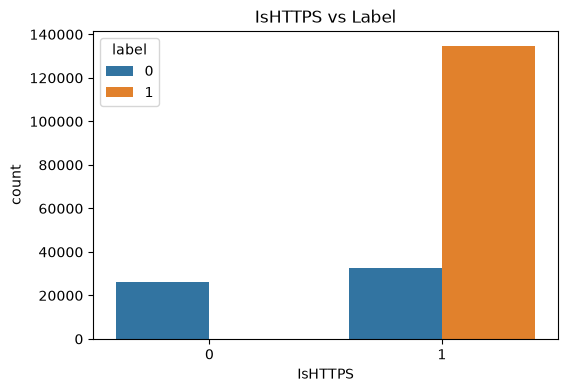

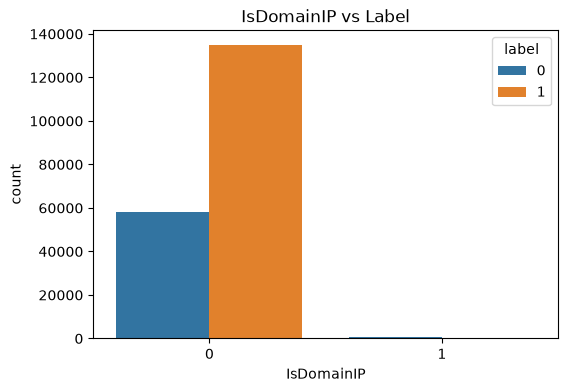

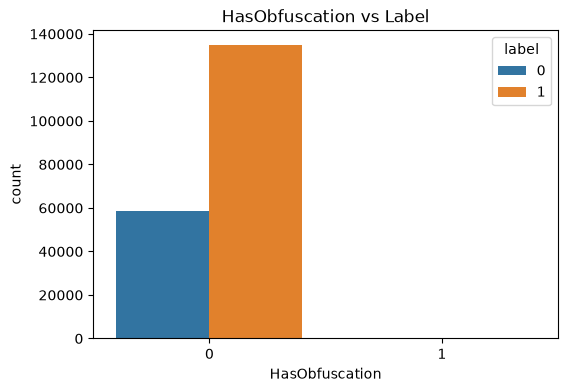

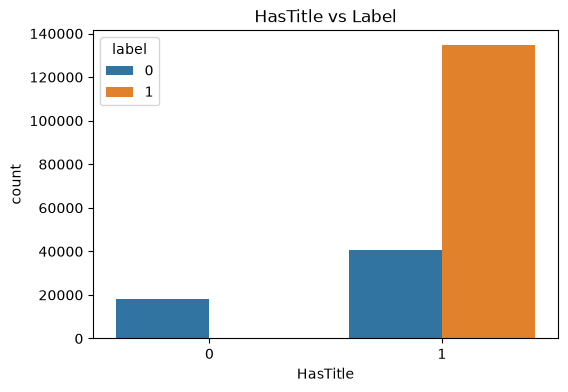

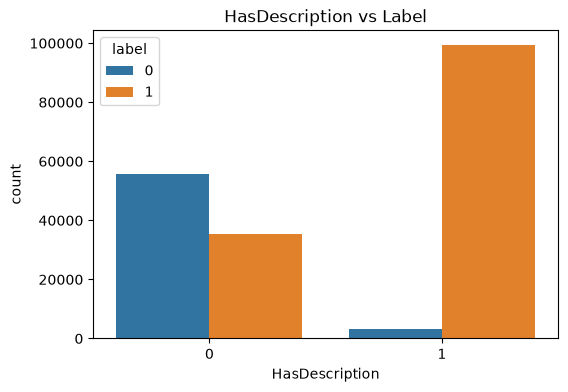

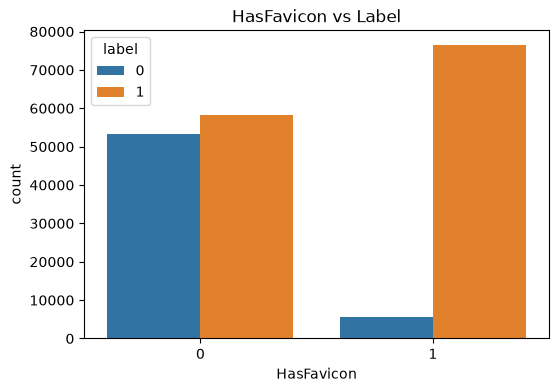

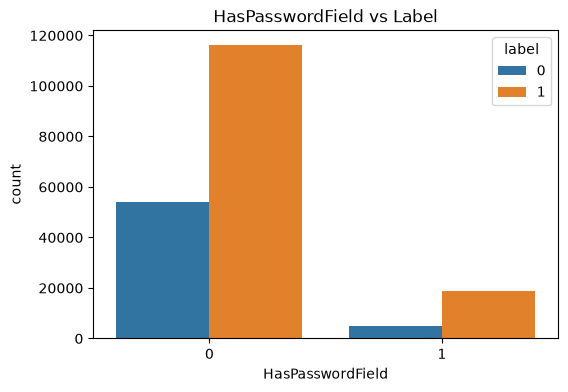

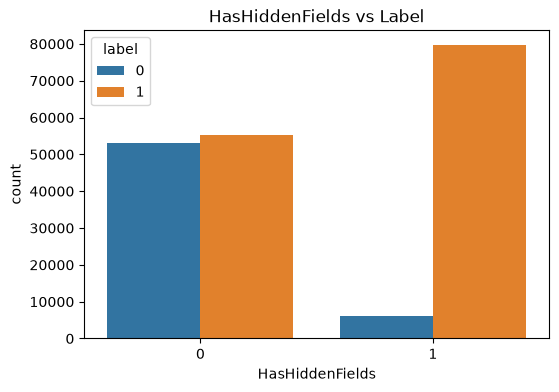

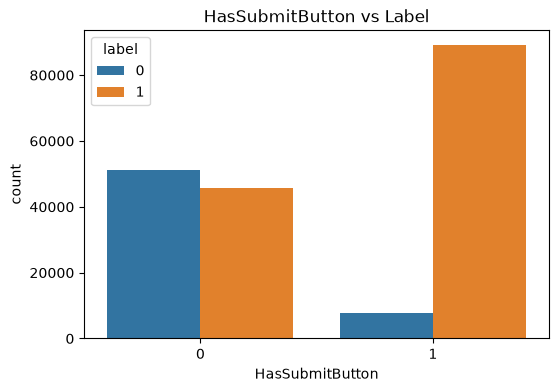

In [26]:
for feature in categorical_features:
    plt.figure(figsize = (6, 4))

    sns.countplot(
        data = data_mod,
        x = feature,
        hue = 'label'
    )

    plt.title(f"{feature} vs Label")
    plt.show()

CORRELATION HEATMAP

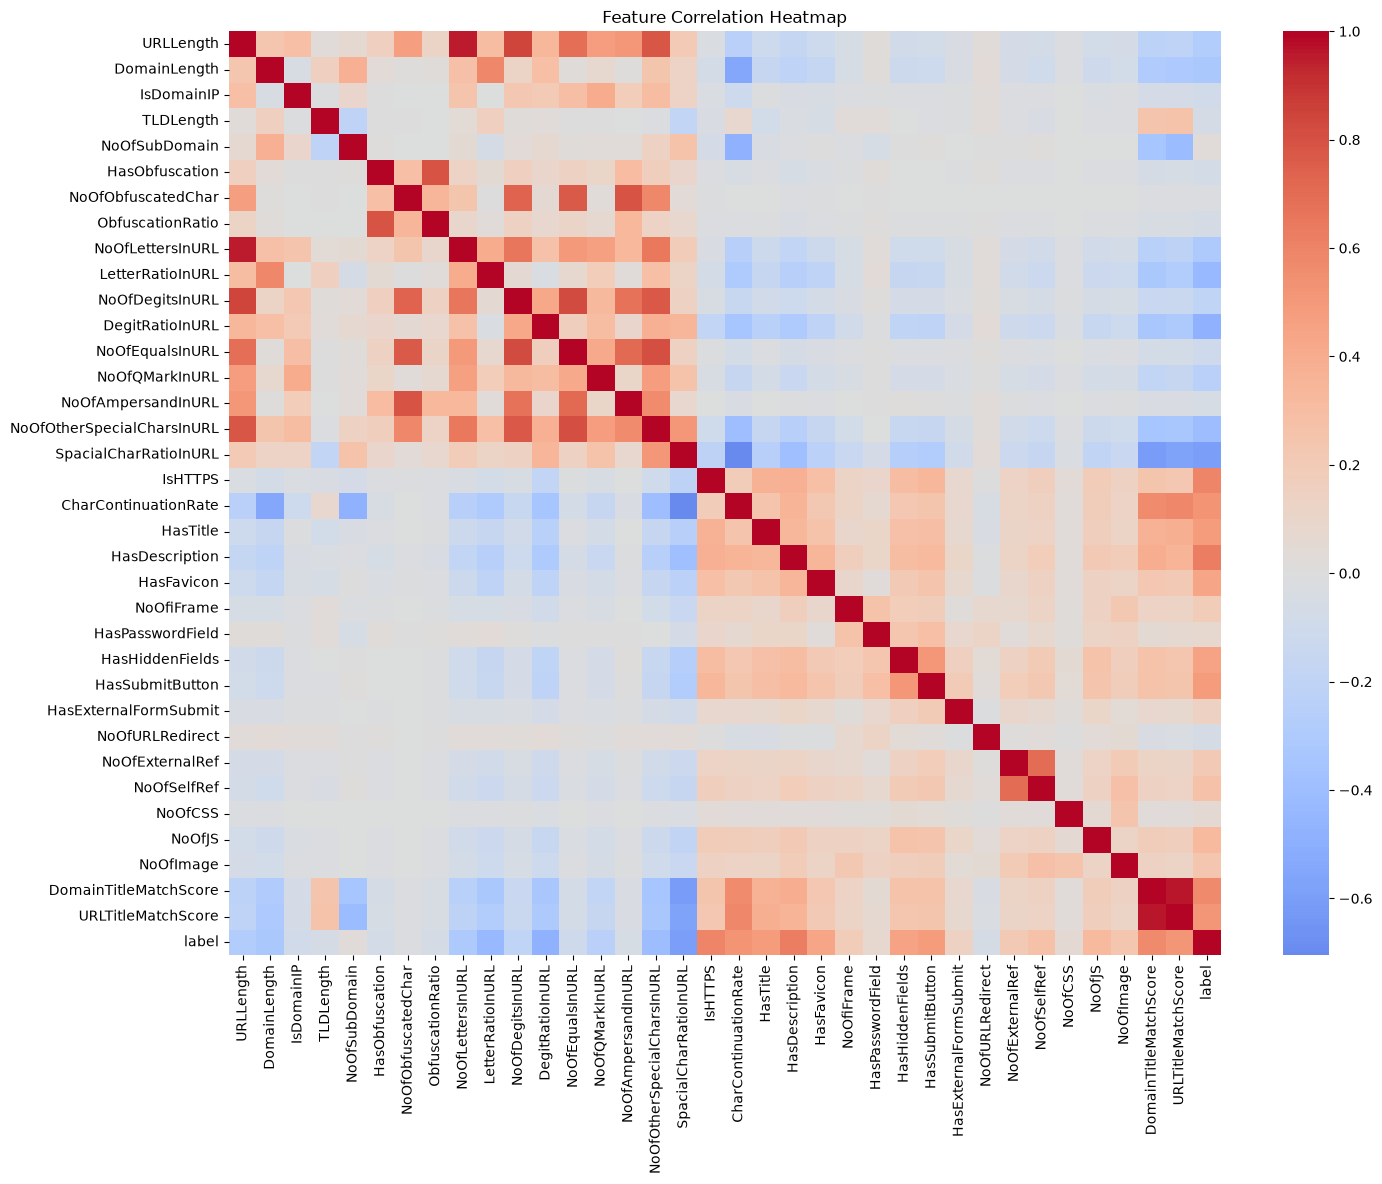

In [28]:
plt.figure(figsize = (16, 12))

corr = data_mod[url_features + webpage_features + ['label']].corr(
    numeric_only=True
)

sns.heatmap(
    corr,
    cmap = 'coolwarm',
    annot = False,
    center = 0
)

plt.title("Feature Correlation Heatmap")
plt.show()

URL LENGTH vs DOMAIN LENGTH

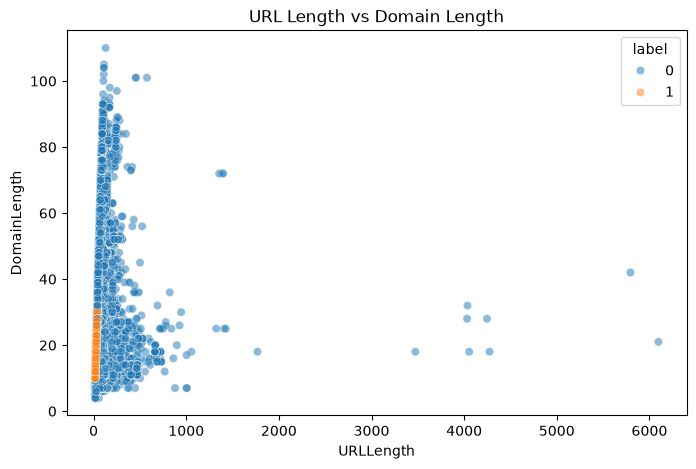

In [31]:
plt.figure(figsize = (8, 5))

sns.scatterplot(
    data = data_mod,
    x = 'URLLength',
    y = 'DomainLength',
    hue = 'label',
    alpha = 0.5
)

plt.title("URL Length vs Domain Length")
plt.show()

In [35]:
data_mod.info()
# tld needs encoding
len(data_mod['TLD'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 193816 entries, 0 to 193815
Data columns (total 38 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URLLength                   193816 non-null  int64  
 1   DomainLength                193816 non-null  int64  
 2   IsDomainIP                  193816 non-null  int64  
 3   TLD                         193816 non-null  str    
 4   CharContinuationRate        193816 non-null  float64
 5   TLDLength                   193816 non-null  int64  
 6   NoOfSubDomain               193816 non-null  int64  
 7   HasObfuscation              193816 non-null  int64  
 8   NoOfObfuscatedChar          193816 non-null  int64  
 9   ObfuscationRatio            193816 non-null  float64
 10  NoOfLettersInURL            193816 non-null  int64  
 11  LetterRatioInURL            193816 non-null  float64
 12  NoOfDegitsInURL             193816 non-null  int64  
 13  DegitRatioInURL          

695

DATA PREPROCESSING

In [42]:
tld_frequencies: dict[str, float] = data_mod['TLD'].value_counts(normalize = True).to_dict()
tld_frequencies

{'com': 0.46674681140875884,
 'org': 0.09131341065753086,
 'uk': 0.032732075783217074,
 'net': 0.03177240269121229,
 'co': 0.020555578486812234,
 'de': 0.020044784744293557,
 'app': 0.018017088372476987,
 'io': 0.0162422091055434,
 'au': 0.015194823956742477,
 'jp': 0.011433524580014034,
 'ru': 0.011252940933669048,
 'edu': 0.009601890452800594,
 'it': 0.009570933256284312,
 'fr': 0.009013703718991208,
 'br': 0.008905353531184216,
 'nl': 0.0087505675486028,
 'ca': 0.008244933338836835,
 'dev': 0.008203657076815123,
 'link': 0.007182069591777768,
 'info': 0.006655797251000949,
 'in': 0.006635159119990094,
 'gov': 0.006573244726957527,
 'pl': 0.006067610517191563,
 'us': 0.005113096957939489,
 'top': 0.004829322656540224,
 'eu': 0.004813844058282082,
 'me': 0.004622941346431667,
 'xyz': 0.0045403888223882445,
 'site': 0.00370454451644859,
 'cn': 0.003658108721674165,
 'es': 0.003601353861394312,
 'se': 0.0035755561976307426,
 'be': 0.0035703966648780285,
 'nz': 0.0031627935774136296,
 'c